In [15]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from utils.utils import * 
import nibabel as nib
import scipy as sc

## LOAD THE DATA 

In [2]:
models_subs = {}

columns = ["x0", "y0", "sigma", "slope", "intercept", "test_var_explained", "var_explained", "mds_ecc", "mds_ang", "roi", "fit_with"]
columns = ["x0", "y0", "sigma", "slope", "intercept", "test_var_explained", "var_explained", "mds_ecc", "mds_ang" ,"roi", "best_roi"]
mode = "train"
rotated = True

#cos_sin = get_prefered_xy(subj_list) # save that and open it matlab 
#print(cos_sin)


for i, sub in enumerate(subj_list):
    models_subs[sub] = {}
    noise_ceilling_file = os.path.join(noise_dir, f'{sub}_noise_ceilling_all_vox.npy')
    noise_ceilling = np.load(noise_ceilling_file, allow_pickle=True)
    for m in models:
      
        m_file = os.path.join(models_dir, f'best_fits_{m}_{sub}_{mode}.npy')
        models_subs[sub][m] = pd.DataFrame(np.load(m_file, allow_pickle=True), columns=columns)
        models_subs[sub][m][columns[:-2]] = models_subs[sub][m][columns[:-2]].astype(np.float32)

In [10]:
# select per ROI 
def cart2pol(x, y):
    rho = np.sqrt(x**2 + y**2)
    phi = np.arctan2(y, x)
    return(rho, phi)
    
x = models_subs['subj01']['oself']['x0']
y = models_subs['subj01']['oself']['y0']
rho, phi = cart2pol(x, y)

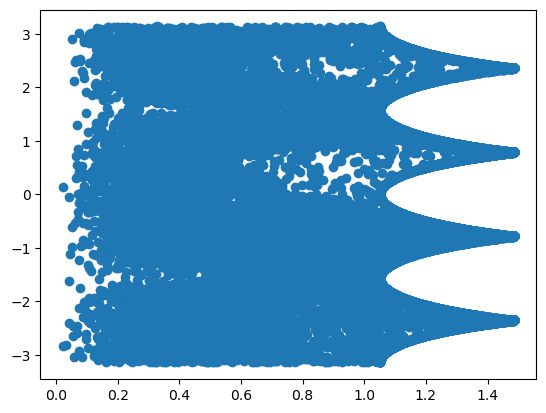

In [14]:
plt.scatter(rho, phi)


In [12]:
phi

0       -1.032764
1       -0.958065
2       -0.827911
3       -1.056584
4       -1.059397
           ...   
33792    1.729453
33793   -1.674687
33794    2.354254
33795   -1.809501
33796   -2.699469
Length: 33797, dtype: float32

In [5]:
#otherwise I can load stuff like this
models_subs['subj08']['oself']

,x0,y0,sigma,slope,intercept,test_var_explained,var_explained,mds_ecc,mds_ang,roi,best_roi
0,-0.902198,-0.763462,7.952625,28.846048,-28.547770,-0.034460,5.595165e-02,1.207349,-2.273094,V2,V2
1,-0.679118,-0.802328,7.848018,29.415709,-29.191757,-0.024535,3.628117e-02,1.051158,-2.439172,V2,V2
2,-1.050000,-0.879881,6.551045,16.528294,-16.226675,-0.033950,5.438703e-02,1.321450,-2.268272,V2,V2
3,-1.047810,-0.835243,16.806753,113.277573,-112.963707,-0.035661,6.013912e-02,1.319711,-2.243786,V2,V2
4,-0.866286,-0.813466,5.637121,13.952250,-13.683886,-0.029580,4.869282e-02,1.180755,-2.324760,V2,V2
...,...,...,...,...,...,...,...,...,...,...,...
32531,1.050000,-0.310706,0.842605,0.553163,-0.238347,0.019078,3.164977e-02,1.321118,1.858497,PHC-2,PHC-2
32532,1.050000,-0.462077,0.702640,0.416896,-0.139787,0.011739,1.886922e-02,1.321118,1.985365,PHC-2,PHC-2
32533,0.546578,0.244162,10.912519,0.000021,0.005230,-0.000475,2.980232e-07,0.970362,1.150682,PHC-2,PHC-2
32534,0.956718,-0.425331,0.375510,0.157185,-0.014529,0.000465,2.028346e-03,1.248264,1.989128,PHC-2,PHC-2


## PRF DATA

In [6]:
prf_subjs = {}
for subj in subj_list:
    # load prf
    prf_path = os.path.join(label_dir, 'freesurfer', subj, 'label', f"lh.prfeccentricity.mgz")
    prf_path_rh = os.path.join(label_dir, 'freesurfer', subj, 'label', f"rh.prfeccentricity.mgz")
    prf_data_lh = nib.load(prf_path).get_fdata().squeeze()
    prf_data_rh = nib.load(prf_path_rh).get_fdata().squeeze()
    prf_data = np.hstack((prf_data_lh, prf_data_rh))

    # load mask 
    if subj == 'subj06' or subj == 'subj08': 
        maskdata_file = os.path.join(mask_dir, subj, f'short.nans.{subj}.testrois.npy')
    else:
        maskdata_file = os.path.join(mask_dir, subj, f'{subj}.testrois.npy')
    maskdata = np.load(maskdata_file, allow_pickle=True).astype(int)

    prf_masked = prf_data[np.where(maskdata != 0)]
    prf_subjs[subj] = prf_masked

In [7]:
prf_subjs

{'subj01': array([1.37070489, 1.2702353 , 1.15341735, ..., 6.00489902, 6.10963392,
        5.82228184], shape=(33797,)),
 'subj02': array([1.94114232, 2.4449389 , 2.87787318, ..., 5.61761475, 5.75126171,
        6.05857849], shape=(35278,)),
 'subj03': array([  5.03009892,   4.79401636,   4.70392466, ..., 166.13000488,
          8.45700169,   2.72865677], shape=(35914,)),
 'subj04': array([2.38706756, 2.32489324, 2.22372055, ..., 4.13956547, 4.43877983,
        4.94921207], shape=(27830,)),
 'subj05': array([4.97662497, 4.80431843, 4.80009556, ..., 2.14613318, 4.86286592,
        4.77740955], shape=(28493,)),
 'subj06': array([1.85621798, 1.82263601, 1.99756467, ..., 2.48292708, 4.52936792,
        5.97801876], shape=(38173,)),
 'subj07': array([4.47733212, 4.66645479, 5.02427769, ..., 4.79990244, 2.94925904,
        4.5623436 ], shape=(27562,)),
 'subj08': array([6.69453096, 6.97134542, 6.62702036, ..., 4.36628103, 3.68420672,
        0.06731689], shape=(32536,))}

In [8]:
# correlation 
# the usual pipeline, do the correlation per hemi and per participants 
# simple spearman 
def work_spearman_downscaled(a, b, sample_size):
    #sample_size = round(a.shape[0] * factor)
    random_sample = random.sample(range(0, a.shape[0]), round(sample_size)) 
    sample_a = a[random_sample]
    sample_b = b[random_sample]
    results = sc.stats.spearmanr(sample_a, sample_b)
    return results.statistic, results.pvalue
def work_spearman_downscaled_averaged(a, b, sample_size, trials):
    rhos, p_values = [], []
    for i in range(trials):
        rho, p = work_spearman_downscaled(a, b, sample_size)
        rhos.append(rho)
        p_values.append(p)
    return np.median(np.asarray(rho)), np.median(np.asarray(p))

rois_corr_2 = {
    'V2': [3,4],
    'V3': [5,6],
}

In [9]:
"""
Threshold is used to determine which data is from the lh, and which is from the rh, since we want to check if hemis is a varible with a satstically significant impact 
"""
import nibabel as nib
threshold = []
for sub in subj_list:
    maskdata_lh_path = os.path.join(mask_dir, sub , f'lh.{sub}.testrois.mgz')
    maskdata_lh = nib.load(maskdata_lh_path).get_fdata().squeeze()
    lh_indices = np.where((maskdata_lh >= 1) & (maskdata_lh <= 15))[0] 
    threshold.append(lh_indices.shape[0])

threshold  # used for lh - rh differentiation 
                

[17901, 19290, 17885, 13606, 14050, 19115, 13976, 15588]

In [10]:
rois = {
    'V1': [1, 2],
    'V2v': [3],
    'V2d': [4],
    'V3v': [5],
    'V3d': [6],
    'hV4': [7],
    'VO-1': [8],
    'VO-2': [9],
    'PHC-1': [10],
    'PHC-2': [11],
    'LO-1': [12],
    'LO-2': [13],
    'TO-1': [14],
    'TO-2': [15]
}
#rois = {'V1': 1, 'V2': 2, 'V3': 3, 'hV4': 4, 'VO-1': 5, 'VO-2': 6,
# 'PHC-1': 7, 'PHC-2': 8, 'LO-1': 9, 'LO-2': 10, 'TO-1': 11, 'TO-2': 12
#}
hemis = ['lh', 'rh']

In [11]:
lh_ecc_x0_corr, lh_ecc_y0_corr, rh_ecc_x0_corr, rh_ecc_y0_corr = np.zeros((len(subj_list), len(rois.keys()))), np.zeros((len(subj_list), len(rois.keys()))), np.zeros((len(subj_list), len(rois.keys()))), np.zeros((len(subj_list), len(rois.keys())))
lh_ecc_x0_corr_ps, lh_ecc_y0_corr_ps, rh_ecc_x0_corr_ps, rh_ecc_y0_corr_ps = np.zeros((len(subj_list), len(rois.keys()))), np.zeros((len(subj_list), len(rois.keys()))), np.zeros((len(subj_list), len(rois.keys()))), np.zeros((len(subj_list), len(rois.keys())))
lh_ecc_x0_corr_ns, lh_ecc_y0_corr_ns, rh_ecc_x0_corr_ns, rh_ecc_y0_corr_ns = np.zeros((len(subj_list), len(rois.keys()))), np.zeros((len(subj_list), len(rois.keys()))), np.zeros((len(subj_list), len(rois.keys()))), np.zeros((len(subj_list), len(rois.keys())))

for m in models:
    for i, sub in enumerate(subj_list):
        if sub == 'subj06' or sub == 'subj08': 
            maskdata_file = os.path.join(mask_dir, sub, f'short.nans.{sub}.testrois.npy')
        else:
            maskdata_file = os.path.join(mask_dir, sub, f'short.{sub}.testrois.npy')
        maskdata = np.load(maskdata_file, allow_pickle=True)

        for hemi in hemis:
            mask_lh = maskdata[:threshold[i]]
            mask_rh = maskdata[threshold[i]:]
            for j, pointer in enumerate(rois.values()):
                
                x_lh = models_subs[sub][m][:threshold[i]][np.isin(mask_lh, pointer)]['x0']
                y_lh = models_subs[sub][m][:threshold[i]][np.isin(mask_lh, pointer)]['y0']
                x_rh = models_subs[sub][m][threshold[i]:][np.isin(mask_rh, pointer)]['x0']
                y_rh = models_subs[sub][m][threshold[i]:][np.isin(mask_rh, pointer)]['y0']

                lh_ecc = prf_subjs[sub][:threshold[i]][np.isin(mask_lh, pointer)]
                rh_ecc = prf_subjs[sub][threshold[i]:][np.isin(mask_rh, pointer)]

                assert lh_ecc.shape == x_lh.shape

                if hemi == 'lh':
                    results_x = sc.stats.spearmanr(x_lh, lh_ecc)  
                    results_y = sc.stats.spearmanr(y_lh, lh_ecc) 
                    lh_ecc_x0_corr[i, j] = results_x.statistic
                    lh_ecc_x0_corr_ps[i, j] = results_x.pvalue
                    lh_ecc_x0_corr_ns[i, j] = lh_ecc.shape[0]
                    lh_ecc_y0_corr[i, j] = results_y.statistic
                    lh_ecc_y0_corr_ps[i, j] = results_y.pvalue
                    lh_ecc_y0_corr_ns[i, j] = lh_ecc.shape[0]
                if hemi == 'rh':
                    results_x = sc.stats.spearmanr(x_rh, rh_ecc)  
                    results_y = sc.stats.spearmanr(y_rh, rh_ecc) 
                    rh_ecc_x0_corr[i, j] = results_x.statistic
                    rh_ecc_x0_corr_ps[i, j] = results_x.pvalue
                    rh_ecc_x0_corr_ns[i, j] = rh_ecc.shape[0]
                    rh_ecc_y0_corr[i, j] = results_y.statistic
                    rh_ecc_y0_corr_ps[i, j] = results_y.pvalue
                    rh_ecc_y0_corr_ns[i, j] = rh_ecc.shape[0]
    
    #LH
    lh_df_x0 = pd.DataFrame(lh_ecc_x0_corr, index=subj_list, columns=rois.keys())
    lh_df_x0_ps = pd.DataFrame(lh_ecc_x0_corr_ps, index=subj_list, columns=rois.keys())
    lh_df_x0_ns = pd.DataFrame(lh_ecc_x0_corr_ns, index=subj_list, columns=rois.keys())
    lh_df_x0.to_csv(f'matlab/x0_pRFecc_correlation_{m}_lh.csv', index=True)
    lh_df_x0_ps.to_csv(f'matlab/x0_pRFecc_correlation_pvalues_{m}_lh.csv', index=True)
    lh_df_x0_ns.to_csv(f'matlab/x0_pRFecc_correlation_nvalues_{m}_lh.csv', index=True)


    lh_df_y0 = pd.DataFrame(lh_ecc_y0_corr, index=subj_list, columns=rois.keys())
    lh_df_y0_ps = pd.DataFrame(lh_ecc_y0_corr_ps, index=subj_list, columns=rois.keys())
    lh_df_y0_ns = pd.DataFrame(lh_ecc_y0_corr_ns, index=subj_list, columns=rois.keys())
    lh_df_y0.to_csv(f'matlab/y0_pRFecc_correlation_{m}_lh.csv', index=True)
    lh_df_y0_ps.to_csv(f'matlab/y0_pRFecc_correlation_pvalues_{m}_lh.csv', index=True)
    lh_df_y0_ns.to_csv(f'matlab/y0_pRFecc_correlation_nvalues_{m}_lh.csv', index=True)
    
    
    
    #RH
    rh_df_x0 = pd.DataFrame(rh_ecc_x0_corr, index=subj_list, columns=rois.keys())
    rh_df_x0_ps = pd.DataFrame(rh_ecc_x0_corr_ps, index=subj_list, columns=rois.keys())
    rh_df_x0_ns = pd.DataFrame(rh_ecc_x0_corr_ns, index=subj_list, columns=rois.keys())
    rh_df_x0.to_csv(f'matlab/x0_pRFecc_correlation_{m}_rh.csv', index=True)
    rh_df_x0_ps.to_csv(f'matlab/x0_pRFecc_correlation_pvalues_{m}_rh.csv', index=True)
    rh_df_x0_ns.to_csv(f'matlab/x0_pRFecc_correlation_nvalues_{m}_rh.csv', index=True)

    rh_df_y0 = pd.DataFrame(rh_ecc_y0_corr, index=subj_list, columns=rois.keys())
    rh_df_y0_ps = pd.DataFrame(rh_ecc_y0_corr_ps, index=subj_list, columns=rois.keys())
    rh_df_y0_ns = pd.DataFrame(rh_ecc_y0_corr_ns, index=subj_list, columns=rois.keys())
    rh_df_y0.to_csv(f'matlab/y0_pRFecc_correlation_{m}_rh.csv', index=True)
    rh_df_y0_ps.to_csv(f'matlab/y0_pRFecc_correlation_pvalues_{m}_rh.csv', index=True)
    rh_df_y0_ns.to_csv(f'matlab/y0_pRFecc_correlation_nvalues_{m}_rh.csv', index=True)

    


In [84]:
rois.values()

dict_values([1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12])

In [26]:
nan_mask

array([ True,  True,  True, ...,  True,  True,  True], shape=(32608,))

In [44]:
s = 'subj01'
threshold[int(s[-1]) -1 ]

17901

In [58]:
models_subs['subj08']['oself'][:threshold[0]][maskdata[:threshold[0]] == 1]

,x0,y0,sigma,slope,intercept,test_var_explained,var_explained,mds_ecc,mds_ang,roi,best_roi
20,-0.250042,-0.759727,2.259520,3.473535,-3.293897,-0.012066,0.012954,0.798914,-2.823639,V1,V1
50,-0.226971,-0.888795,3.603895,8.158161,-7.990448,-0.009684,0.010330,0.791997,-2.891567,V1,V1
51,-0.119072,1.050000,2.528353,4.135729,-3.974608,-0.001757,0.006383,0.768064,-0.112919,V1,V1
56,0.373834,0.319932,0.025250,0.468222,0.013760,-0.002604,0.000140,0.845870,0.862938,V1,V1
57,-0.115737,0.111414,3.583254,6.810771,-6.675873,-0.003327,0.004489,0.767554,-0.804429,V1,V1
...,...,...,...,...,...,...,...,...,...,...,...
17814,-0.358416,0.726154,6.234605,49.589428,-49.208927,-0.034743,0.082535,0.839170,-0.458500,V1,V1
17815,-0.308270,0.692474,4.917552,35.952545,-35.539349,-0.036118,0.089718,0.819008,-0.418832,V1,V1
17822,-0.305451,0.761589,6.459475,50.219791,-49.883953,-0.021281,0.058051,0.817951,-0.381430,V1,V1
17823,-0.238044,0.588476,6.438790,59.799435,-59.428123,-0.027951,0.062090,0.795241,-0.384388,V1,V1


In [67]:
models_subs['subj08']['oself'][threshold[0]:][maskdata[threshold[0]:] == 1]

,x0,y0,sigma,slope,intercept,test_var_explained,var_explained,mds_ecc,mds_ang,roi,best_roi
17976,0.503945,-0.388227,5.015181,6.710529,-6.618793,0.010491,0.006335,0.910881,2.227212,V1,V1
17987,1.049986,-0.135530,17.357460,27.384878,-27.316652,0.003846,0.003028,1.295459,1.699164,V1,V1
17988,-0.126074,0.010850,0.025691,0.891769,-0.000477,0.000373,0.000377,0.769180,-1.484946,V1,V1
17989,0.330592,-0.669743,3.707608,9.061016,-8.880964,0.009788,0.019299,0.827668,2.683070,V1,V1
17997,1.050000,-0.190214,9.407887,8.127549,-8.058336,0.003227,0.003089,1.295470,1.750008,V1,V1
...,...,...,...,...,...,...,...,...,...,...,...
27262,-0.007220,1.050000,0.042089,0.487887,0.003992,0.000899,0.000418,0.758812,-0.006876,V1,V1
27263,1.050000,-0.081714,5.877126,9.488506,-9.280176,0.018302,0.026324,1.295470,1.648463,V1,V1
27503,0.758219,-0.187463,7.012365,38.463184,-38.060280,0.043452,0.112600,1.072678,1.813176,V1,V1
27519,0.929533,-0.179990,9.545226,59.947643,-59.510460,0.045125,0.117314,1.199906,1.762065,V1,V1


In [107]:
maskdata

array([2., 2., 2., ..., 3., 3., 3.], shape=(33797,))

In [111]:
np.isin(maskdata, [1, 2])

array([ True,  True,  True, ..., False, False, False], shape=(33797,))